# Huấn luyện & Đánh giá Cấp 8 (AlphaZero-inspired Self-Play + Arena Gating) trên Google Colab

Notebook này huấn luyện **Level 8 (`Level8AlphaZeroAgent`)** theo chu trình **Self-Play → Replay Buffer Refinement → Checkpoint Arena Gating (>= 55%)** trên **T4 GPU**, **ghi trực tiếp mọi checkpoint và log ra Google Drive** để không bao giờ mất dữ liệu nếu Colab ngắt phiên.

**Các nâng cấp đã tích hợp:**
- **Warm-start từ Level 5 mới** (`best_model.pt` đạt Top-1 34.41%, Value MSE 0.6983).
- **Tăng tốc 3–4x trên GPU**: Batched Virtual Loss (`batch_size=8` trên CUDA), Zobrist Eval Cache, Subtree Reuse và Forced Move shortcut trong cả Self-Play lẫn Arena.
- **Chống Catastrophic Forgetting**: `lr = 1e-4`, `train_steps = 40`, `value_weight = 1.5`.
- **Thống kê chuẩn học thuật**: Tự động tính khoảng tin cậy **Wilson 95%** cho Arena Gating (`--arena-games 20`).

**Chuẩn bị:** Chọn **Runtime → Change runtime type → T4 GPU** và đảm bảo đã có `MyDrive/chess_ai/output_l5/best_model.pt` (hoặc lấy từ `checkpoints/best_model.pt` trong repo).

In [2]:
# 1. Kiểm tra GPU & Mount Google Drive
import torch
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
!nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv

from google.colab import drive
drive.mount('/content/drive')

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
name, memory.total [MiB], memory.free [MiB]
Tesla T4, 15360 MiB, 14910 MiB
Mounted at /content/drive


In [3]:
# 2. Cấu hình đường dẫn, Clone/Pull repo và cài đặt thư viện
from pathlib import Path

REPO_URL = 'https://github.com/VoVanTuan284/101_TTNTNC.git'
BRANCH = 'feat-level5-colab-results'  # Đổi thành 'main' sau khi đã merge PR
REPO_DIR = Path('/content/101_TTNTNC')

DRIVE_BASE = Path('/content/drive/MyDrive/chess_ai')
DRIVE_L5_CKPT = DRIVE_BASE / 'output_l5' / 'best_model.pt'
DRIVE_L8_CKPT_DIR = DRIVE_BASE / 'output_l8' / 'checkpoints'
DRIVE_L8_RES_DIR = DRIVE_BASE / 'output_l8' / 'results'
DRIVE_L8_CKPT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_L8_RES_DIR.mkdir(parents=True, exist_ok=True)

if not REPO_DIR.exists():
    !git clone -b {BRANCH} {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git fetch origin
    !git checkout {BRANCH}
    !git pull origin {BRANCH}

%cd {REPO_DIR}
!pip install -q python-chess pyyaml matplotlib

# Tự chọn checkpoint warm-start: ưu tiên file trên Drive, fallback sang repo checkpoints/best_model.pt
WARM_START = DRIVE_L5_CKPT if DRIVE_L5_CKPT.exists() else (REPO_DIR / 'checkpoints' / 'best_model.pt')
assert WARM_START.exists(), f'Không tìm thấy best_model.pt tại {WARM_START}!'
print('Warm-start checkpoint:', WARM_START, f'({WARM_START.stat().st_size / (1024*1024):.1f} MB)')

Cloning into '/content/101_TTNTNC'...
remote: Enumerating objects: 1194, done.
remote: Counting objects: 100% (99/99), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 1194 (delta 59), reused 64 (delta 55), pack-reused 1095 (from 1)
Receiving objects: 100% (1194/1194), 203.72 MiB | 19.99 MiB/s, done.
Resolving deltas: 100% (559/559), done.
/content/101_TTNTNC
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Warm-start checkpoint: /content/101_TTNTNC/checkpoints/best_model.pt (53.7 MB)


In [4]:
# 3. Chạy vòng lặp Self-Play -> Refinement -> Arena Gating (ghi thẳng ra Google Drive)
# Đổi RESUME = True nếu muốn chạy tiếp từ l8_alphazero_latest.pt (ví dụ tăng ITERATIONS từ 6 lên 10)
RESUME = False
ITERATIONS = 6
GAMES_PER_ITER = 20
MCTS_SIMS = 100
ARENA_GAMES = 20
TRAIN_STEPS = 40
LR = 1e-4

LATEST_CKPT = DRIVE_L8_CKPT_DIR / 'l8_alphazero_latest.pt'
resume_arg = f'--resume "{LATEST_CKPT}"' if (RESUME and LATEST_CKPT.exists()) else ''

!python -m chess_ai.training.selfplay \
  --warm-start "{WARM_START}" \
  --checkpoint-dir "{DRIVE_L8_CKPT_DIR}" \
  --output-dir "{DRIVE_L8_RES_DIR}" \
  --iterations {ITERATIONS} \
  --games-per-iter {GAMES_PER_ITER} \
  --sims {MCTS_SIMS} \
  --arena-games {ARENA_GAMES} \
  --train-steps {TRAIN_STEPS} \
  --lr {LR} \
  {resume_arg}

Bắt đầu huấn luyện Cấp 8 (AlphaZero Self-Play) trên thiết bị: cuda | Warm-start L5: True (/content/101_TTNTNC/checkpoints/best_model.pt) | Iterations: 1->6 | Self-Play: 20 ván/iter (100 sims/nước, max_plies=160) | Arena Gating: 20 ván (ngưỡng >= 55%)
  [Iter 1/6] Pha 1 (Self-Play): Ván 20/20 (96 plies, kq=+0) | Buffer: 2,217 mẫu
  [Iter 1/6] Pha 2 (Refinement): 40 steps | Loss: 2.9223 (Policy: 2.4588, Value: 0.3090)
  [Iter 1/6] Pha 3 (Arena Gating): Ván 20/20 | W:6 D:6 L:8 (Score:  45.0%)
  ==> [Iter 1/6 Hoàn tất] Arena Score: 45.0% (W:6 D:6 L:8) -> REJECTED (Giữ nguyên Champion) | Champion v0 | 341.2s

  [Iter 2/6] Pha 1 (Self-Play): Ván 20/20 (127 plies, kq=+1) | Buffer: 4,217 mẫu
  [Iter 2/6] Pha 2 (Refinement): 40 steps | Loss: 3.0137 (Policy: 2.4961, Value: 0.3451)
  [Iter 2/6] Pha 3 (Arena Gating): Ván 20/20 | W:9 D:2 L:9 (Score:  50.0%)
  ==> [Iter 2/6 Hoàn tất] Arena Score: 50.0% (W:9 D:2 L:9) -> REJECTED (Giữ nguyên Champion) | Champion v0 | 304.9s

  [Iter 3/6] Pha 1 (Self-P

## 4. Phân tích kết quả & Vẽ biểu đồ Self-Play + Arena Gating
Vẽ 2 biểu đồ chính lưu trực tiếp ra Google Drive (`fig_level8_selfplay_gating.png`):
1. **Arena Gating Score (%)** kèm thanh sai số **Wilson 95% CI**, đường ngưỡng **55%** và đánh dấu các vòng **ACCEPTED** (cập nhật Champion mới).
2. **Training Loss** (`Total`, `Policy`, `Value`) và kích thước Replay Buffer theo từng Iteration.

Thiết bị: cuda | Iterations: 6 | Champion version: v0 | Buffer: 12,534 mẫu
--------------------------------------------------------------------------------------------
Iter  1 | Buf= 2217 | Loss=2.9223 (P=2.4588, V=0.3090) | Arena= 45.0% (6W-6D-8L, CI95=[25.8%,65.8%]) -> rejected (341s)
Iter  2 | Buf= 4217 | Loss=3.0137 (P=2.4961, V=0.3451) | Arena= 50.0% (9W-2D-9L, CI95=[29.9%,70.1%]) -> rejected (305s)
Iter  3 | Buf= 6389 | Loss=3.0220 (P=2.4682, V=0.3692) | Arena= 37.5% (5W-5D-10L, CI95=[20.0%,59.1%]) -> rejected (296s)
Iter  4 | Buf= 8437 | Loss=3.0668 (P=2.4841, V=0.3885) | Arena= 35.0% (6W-2D-12L, CI95=[18.1%,56.7%]) -> rejected (305s)
Iter  5 | Buf=10605 | Loss=3.2018 (P=2.4974, V=0.4696) | Arena= 50.0% (8W-4D-8L, CI95=[29.9%,70.1%]) -> rejected (338s)
Iter  6 | Buf=12534 | Loss=3.1792 (P=2.4840, V=0.4635) | Arena= 42.5% (6W-5D-9L, CI95=[23.8%,63.6%]) -> rejected (336s)


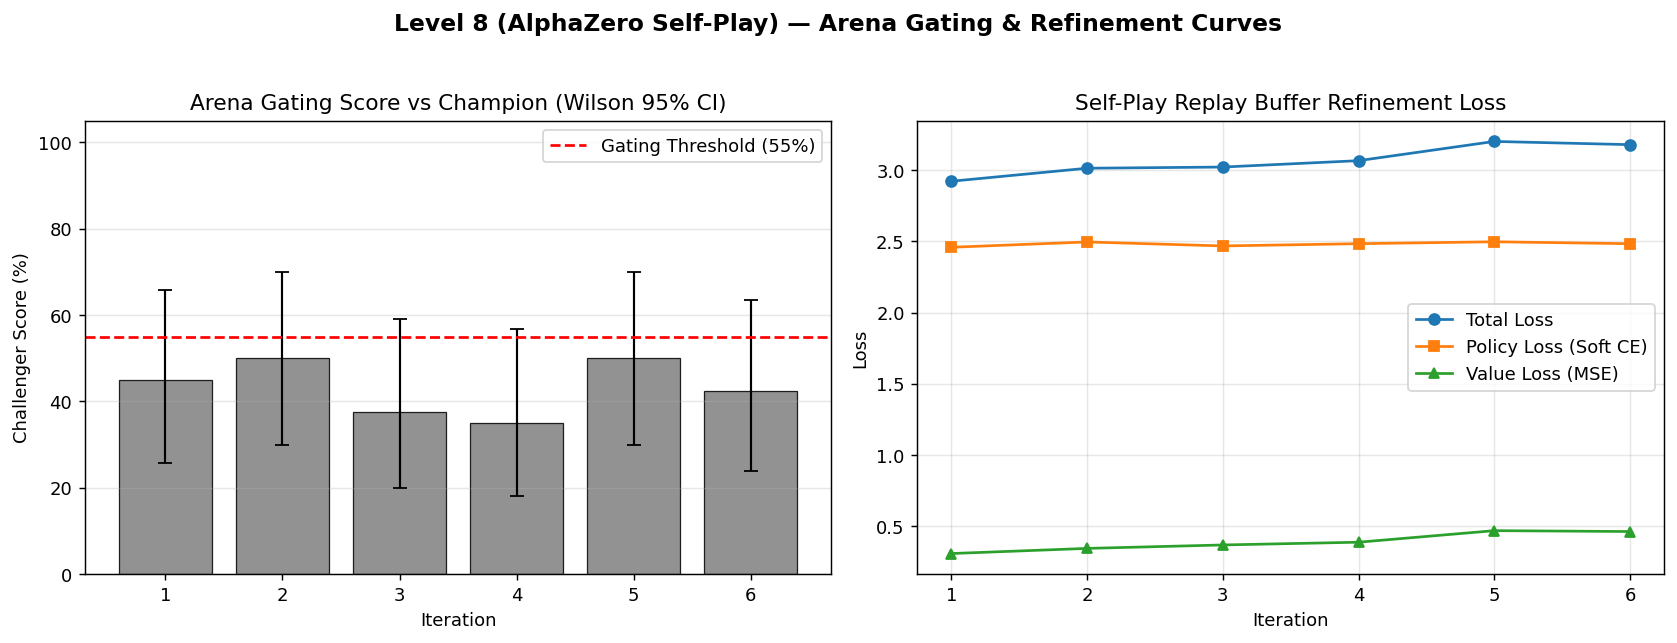

Đã lưu biểu đồ tại: /content/drive/MyDrive/chess_ai/output_l8/results/fig_level8_selfplay_gating.png


In [5]:
import json
import matplotlib.pyplot as plt
import numpy as np

metrics_file = DRIVE_L8_RES_DIR / 'selfplay_metrics.json'
assert metrics_file.exists(), f'Chưa thấy {metrics_file}'
sp = json.loads(metrics_file.read_text(encoding='utf-8'))
hist = sp.get('history', [])

iters = [h['iteration'] for h in hist]
scores = [h['arena']['score_rate'] * 100.0 for h in hist]
accepted = [h['arena']['accepted'] for h in hist]
cis = [h['arena'].get('wilson_ci_95', [h['arena']['score_rate'], h['arena']['score_rate']]) for h in hist]
err_low = [max(0.0, s - ci[0] * 100.0) for s, ci in zip(scores, cis)]
err_high = [max(0.0, ci[1] * 100.0 - s) for s, ci in zip(scores, cis)]

p_loss = [h['train_policy_loss'] for h in hist]
v_loss = [h['train_value_loss'] for h in hist]
t_loss = [h['train_total_loss'] for h in hist]
buf_sz = [h['buffer_size'] for h in hist]

print(f"Thiết bị: {sp.get('device')} | Iterations: {sp.get('iterations_completed')} | Champion version: v{sp.get('champion_version')} | Buffer: {sp.get('buffer_size'):,} mẫu")
print('-' * 92)
for h in hist:
    a = h['arena']
    tag = 'ACCEPTED ★' if a['accepted'] else 'rejected'
    ci = a.get('wilson_ci_95', [0, 0])
    print(f"Iter {h['iteration']:2d} | Buf={h['buffer_size']:5d} | Loss={h['train_total_loss']:.4f} (P={h['train_policy_loss']:.4f}, V={h['train_value_loss']:.4f}) "
          f"| Arena={a['score_rate']*100:5.1f}% ({a['wins']}W-{a['draws']}D-{a['losses']}L, CI95=[{ci[0]*100:.1f}%,{ci[1]*100:.1f}%]) -> {tag} ({h['elapsed_sec']:.0f}s)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=130)
fig.suptitle('Level 8 (AlphaZero Self-Play) — Arena Gating & Refinement Curves', fontsize=13, fontweight='bold')

# (1) Arena Score + Wilson 95% CI
colors = ['#2ca02c' if acc else '#7f7f7f' for acc in accepted]
ax1.bar(iters, scores, color=colors, alpha=0.85, edgecolor='black', linewidth=0.7)
ax1.errorbar(iters, scores, yerr=[err_low, err_high], fmt='none', ecolor='black', capsize=4, linewidth=1.2)
ax1.axhline(55.0, color='red', linestyle='--', linewidth=1.5, label='Gating Threshold (55%)')
ax1.set_title('Arena Gating Score vs Champion (Wilson 95% CI)')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Challenger Score (%)')
ax1.set_xticks(iters)
ax1.set_ylim(0, 105)
ax1.grid(True, axis='y', alpha=0.3)
ax1.legend()

# (2) Training Loss
ax2.plot(iters, t_loss, marker='o', label='Total Loss')
ax2.plot(iters, p_loss, marker='s', label='Policy Loss (Soft CE)')
ax2.plot(iters, v_loss, marker='^', label='Value Loss (MSE)')
ax2.set_title('Self-Play Replay Buffer Refinement Loss')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Loss')
ax2.set_xticks(iters)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout(rect=[0, 0, 1, 0.95])
fig_out = DRIVE_L8_RES_DIR / 'fig_level8_selfplay_gating.png'
plt.savefig(fig_out, dpi=150)
plt.show()
print('Đã lưu biểu đồ tại:', fig_out)

In [6]:
# 5. Kiểm tra nhanh đối đầu Level 8 (Champion mới) vs Level 7 (Baseline Level 5) - 10 ván ghép cặp
from chess_ai.agents.level7_guided_mcts import Level7GuidedMCTSAgent
from chess_ai.agents.level8_alphazero import Level8AlphaZeroAgent
from chess_ai.arena.tournament import run_paired_matchup
from chess_ai.utils.epd import load_epd_file

BEST_L8 = DRIVE_L8_CKPT_DIR / 'l8_alphazero_best.pt'
a8 = Level8AlphaZeroAgent(checkpoint_path=str(BEST_L8), simulations=100, eval_mode=True, allow_untrained_fallback=False)
a7 = Level7GuidedMCTSAgent(checkpoint_path=str(WARM_START), simulations=100, eval_mode=True, allow_untrained_fallback=False)

openings = load_epd_file('resources/openings_50.epd')[:5]  # 5 khai cuộc x 2 màu = 10 ván
res = run_paired_matchup(
    agent_a=a8,
    agent_b=a7,
    openings=openings,
    seeds=[42],
    budget_mode='workload_control',
    workload_a=100,
    workload_b=100,
    max_plies=160,
)
print(f"Level 8 vs Level 7 (100 sims, 10 ván): Score={res['score']*100:.1f}% (W:{res['wins']} D:{res['draws']} L:{res['losses']}) | Wilson95={res['wilson_ci_95']}")

Level 8 vs Level 7 (100 sims, 10 ván): Score=50.0% (W:5 D:0 L:5) | Wilson95=[0.2366, 0.7634]


In [7]:
# 6. Liệt kê toàn bộ file đầu ra đã lưu an toàn trên Google Drive
print('=== FILE ĐÃ LƯU TRÊN GOOGLE DRIVE ===')
for folder in (DRIVE_L8_CKPT_DIR, DRIVE_L8_RES_DIR):
    for f in sorted(folder.iterdir()):
        print(f'  - {f} ({f.stat().st_size / 1024:.1f} KB)')

=== FILE ĐÃ LƯU TRÊN GOOGLE DRIVE ===
  - /content/drive/MyDrive/chess_ai/output_l8/checkpoints/l8_alphazero_best.pt (18349.9 KB)
  - /content/drive/MyDrive/chess_ai/output_l8/checkpoints/l8_alphazero_latest.pt (277245.8 KB)
  - /content/drive/MyDrive/chess_ai/output_l8/results/fig_level8_selfplay_gating.png (91.9 KB)
  - /content/drive/MyDrive/chess_ai/output_l8/results/selfplay_metrics.json (3.7 KB)
